# Team Setup Guide

**Welcome to the LLM Grouping Loss Experiment!**

This notebook allows you to:
- **Experiment with different clustering methods** (KMeans, DBSCAN, Hierarchical, etc.)
- **Test different prompting strategies** to see how they affect model confidence
- **Compare results** using the same visualizations and metrics

## Important Notes for Team Members:

### 🖥️ Hardware Requirements
- **GPU (Recommended)**: Uses 4-bit quantization, ~4-6GB VRAM, faster inference (run this in googlecolab with gpu instance or locally if u have nvidia GPU)
- **CPU (Supported)**: Uses float32, ~14-16GB RAM, **expect 10-20x slower inference**
  - For CPU: Consider testing on a small subset first (e.g., 100 samples)
  - Or switch to smaller models like `microsoft/phi-2` or `TinyLlama/TinyLlama-1.1B-Chat-v1.0`

### 📝 What You Need to Modify:

1. **Configuration Cell Below**: Change `MODEL_NAME`, `CLUSTERING_METHOD`, `PROMPT_STYLE`, etc.
2. **Clustering Section**: Implement your own clustering algorithm (keep the same output: `labels` and `n_clusters`)
3. **Cluster Names**: After running your clustering, manually create meaningful cluster names (see instructions in that section)
4. **Prompt Templates**: Add your own prompt variations to the `PROMPT_TEMPLATES` dictionary

### 🎯 Goal
Each team member produces comparable results (same metrics, visualizations) so we can analyze how clustering methods and prompts affect model confidence patterns.

In [32]:
# ============================================================================
# CONFIGURATION - MODIFY THESE PARAMETERS FOR YOUR EXPERIMENTS
# ============================================================================

import torch

# Model Configuration
MODEL_NAME = "mistralai/Mistral-7B-Instruct-v0.2"  # Change to any HuggingFace model
# Alternatives for CPU: "microsoft/phi-2", "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

# Hardware Configuration (auto-detected, but you can override)
USE_GPU = torch.cuda.is_available()
print(f"🖥️  Hardware: {'GPU' if USE_GPU else 'CPU'}")
if not USE_GPU:
    print("⚠️  Running on CPU - expect slower inference (~10-20x)")
    print("💡 Tip: Test on small subset first or use smaller model")

# Clustering Configuration
CLUSTERING_METHOD = "kmeans"  # Options: "kmeans", "dbscan", "hierarchical", "custom"

# Prompt Configuration
PROMPT_STYLE = "verbose"  # Options: "verbose", "direct", "custom"
# See PROMPT_TEMPLATES below to add your own styles

# LLM Generation Configuration
BATCH_SIZE = 32 if USE_GPU else 4  # Reduce for CPU to avoid memory issues
MAX_NEW_TOKENS = 100

# Sample Size Configuration (FOR LLM GENERATION)
USE_SAMPLE = False  # Set to True to test on a small subset, False for all data
SAMPLE_SIZE = 20    # Number of samples to use if USE_SAMPLE=True

# Reproducibility
RANDOM_SEED = 42

print(f"✓ Configuration loaded:")
print(f"  - Model: {MODEL_NAME}")
print(f"  - Clustering: {CLUSTERING_METHOD}")
print(f"  - Prompt Style: {PROMPT_STYLE}")
print(f"  - Batch Size: {BATCH_SIZE}")
print(f"  - Sample Mode: {'Yes - ' + str(SAMPLE_SIZE) + ' samples' if USE_SAMPLE else 'No - All data'}")
print(f"  - Random Seed: {RANDOM_SEED}")

🖥️  Hardware: GPU
✓ Configuration loaded:
  - Model: mistralai/Mistral-7B-Instruct-v0.2
  - Clustering: kmeans
  - Prompt Style: verbose
  - Batch Size: 32
  - Sample Mode: No - All data
  - Random Seed: 42


# Resumes data test

- test multiple clustering methods
- see if there are interesting results

## DATA + Embedding + Normalization + PCA

In [33]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt

# Set all random seeds
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

#https://www.kaggle.com/datasets/anselerol/job-postings-and-resumes-with-embeddings-faiss?resource=download
df = pd.read_csv('../data/resumes.csv')
df['name'] = df['text'].apply(lambda x: x.split('Summary')[0].strip())
# Sort dataframe by 'id' to ensure consistent ordering
df = df.sort_values('id').reset_index(drop=True)
print(f"✓ Random seeds set to {RANDOM_SEED}")
print(f"✓ DataFrame sorted by 'id' and reset: {len(df)} rows")

✓ Random seeds set to 42
✓ DataFrame sorted by 'id' and reset: 2484 rows


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         2484 non-null   int64 
 1   text       2484 non-null   object
 2   name       2484 non-null   object
 3   embedding  2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB


In [35]:
df.head()

,id,text,name,embedding
0,1,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,"[-0.04447828233242035, 0.021229209378361702, 0..."
1,2,"HR SPECIALIST, US HR OPERATIONS ...","HR SPECIALIST, US HR OPERATIONS","[-0.05166391283273697, 0.01624675653874874, 0...."
2,3,HR DIRECTOR Summary Over 2...,HR DIRECTOR,"[-0.04784499853849411, 0.019322028383612633, -..."
3,4,HR SPECIALIST Summary Dedica...,HR SPECIALIST,"[-0.10490810126066208, 0.011350762099027634, 0..."
4,5,HR MANAGER Skill Highlights ...,HR MANAGER Skill Highlights ...,"[-0.06549879908561707, 0.04003952443599701, -0..."


In [36]:
from sklearn.preprocessing import StandardScaler, normalize
import ast  # Pour convertir les chaînes en listes si nécessaire

# Conversion des embeddings si stockés en chaîne
def convert_embedding(embedding_str):
    """Convertit une chaîne en liste numpy array"""
    if isinstance(embedding_str, str):
        return np.array(ast.literal_eval(embedding_str))
    elif isinstance(embedding_str, list):
        return np.array(embedding_str)
    else:
        return embedding_str

# Appliquer la conversion
df['embeddings_array'] = df['embedding'].apply(convert_embedding)

# Vérifier la dimension des embeddings
embedding_dim = len(df['embeddings_array'].iloc[0])
print(f"Dimension des embeddings : {embedding_dim}")

# Créer la matrice d'embeddings => c'est sur cette matrice qu'on va calculer les clusters
embeddings_matrix = np.vstack(df['embeddings_array'].values)
print(f"Shape de la matrice d'embeddings : {embeddings_matrix.shape}")

# Normaliser les données
scaler = StandardScaler()
#embeddings_matrix_normalized = scaler.fit_transform(embeddings_matrix)
embeddings_matrix_normalized = normalize(embeddings_matrix, norm='l2')

Dimension des embeddings : 384
Shape de la matrice d'embeddings : (2484, 384)


In [37]:
from sklearn.decomposition import PCA

# pca = PCA(n_components=min(50, embedding_dim), random_state=RANDOM_SEED)  # Added random_state for reproducibility
# embeddings_reduced = pca.fit_transform(embeddings_matrix_normalized)
# embeddings_reduced = normalize(embeddings_reduced, norm='l2')
# print(f"Variance expliquée par les {pca.n_components_} composantes : {pca.explained_variance_ratio_.sum():.2%}")

embeddings_reduced = embeddings_matrix_normalized

## Clustering Methods

**For Teammates**: This section demonstrates KMeans clustering. You can:
1. Keep KMeans and change parameters (different k values)
2. Replace with your own clustering method (DBSCAN, Hierarchical, etc.)
3. Compare multiple methods

**Important**: Your clustering MUST produce these outputs for downstream compatibility:
- `labels` or `cluster_labels`: NumPy array of cluster assignments (one per sample)
- `n_clusters`: Integer number of clusters found
- Add these to dataframe: `df['cluster'] = labels`

### KMeans Clustering (Original Method)

In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Initialize storage
metrics = {
    'silhouette': [],
    'davies_bouldin': [],
    'calinski_harabasz': [],
    'inertia': []
}

K_range = range(2, 30)  # reasonable range

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(embeddings_reduced)
    # Compute metrics
    metrics['silhouette'].append(silhouette_score(embeddings_reduced, labels))
    metrics['davies_bouldin'].append(davies_bouldin_score(embeddings_reduced, labels))
    metrics['calinski_harabasz'].append(calinski_harabasz_score(embeddings_reduced, labels))
    metrics['inertia'].append(kmeans.inertia_)

    print(f"k={k}: Sil={metrics['silhouette'][-1]:.4f}, "
          f"DB={metrics['davies_bouldin'][-1]:.2f}, "
          f"CH={metrics['calinski_harabasz'][-1]:.0f}")

# Find best k for each metric
best_k_sil = K_range[np.argmax(metrics['silhouette'])]
best_k_db = K_range[np.argmin(metrics['davies_bouldin'])]  # lower is better
best_k_ch = K_range[np.argmax(metrics['calinski_harabasz'])]

print(f"\nBest k by Silhouette: {best_k_sil}")
print(f"Best k by Davies-Bouldin: {best_k_db}")
print(f"Best k by Calinski-Harabasz: {best_k_ch}")

k=2: Sil=0.0423, DB=4.87, CH=104
k=3: Sil=0.0399, DB=4.08, CH=100
k=4: Sil=0.0516, DB=3.67, CH=100
k=5: Sil=0.0599, DB=3.28, CH=95
k=6: Sil=0.0659, DB=3.23, CH=91
k=7: Sil=0.0648, DB=3.20, CH=86
k=8: Sil=0.0667, DB=3.03, CH=82
k=9: Sil=0.0711, DB=3.10, CH=79
k=10: Sil=0.0680, DB=3.11, CH=75
k=11: Sil=0.0722, DB=3.06, CH=72
k=12: Sil=0.0739, DB=3.12, CH=68
k=13: Sil=0.0762, DB=3.08, CH=65
k=14: Sil=0.0678, DB=3.24, CH=62
k=15: Sil=0.0694, DB=3.16, CH=60
k=16: Sil=0.0723, DB=3.19, CH=58
k=17: Sil=0.0701, DB=3.25, CH=56
k=18: Sil=0.0701, DB=3.28, CH=54
k=19: Sil=0.0696, DB=3.20, CH=52
k=20: Sil=0.0717, DB=3.13, CH=50
k=21: Sil=0.0692, DB=3.31, CH=48
k=22: Sil=0.0666, DB=3.35, CH=46
k=23: Sil=0.0658, DB=3.32, CH=45
k=24: Sil=0.0675, DB=3.45, CH=43
k=25: Sil=0.0642, DB=3.32, CH=42
k=26: Sil=0.0606, DB=3.43, CH=41
k=27: Sil=0.0656, DB=3.49, CH=40
k=28: Sil=0.0604, DB=3.50, CH=39
k=29: Sil=0.0577, DB=3.40, CH=38

Best k by Silhouette: 13
Best k by Davies-Bouldin: 8
Best k by Calinski-Harabasz

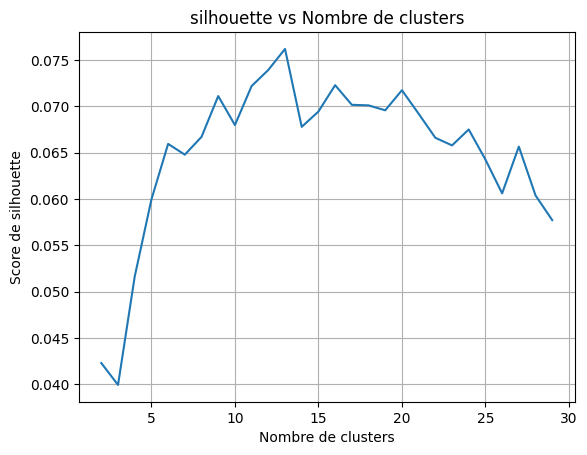

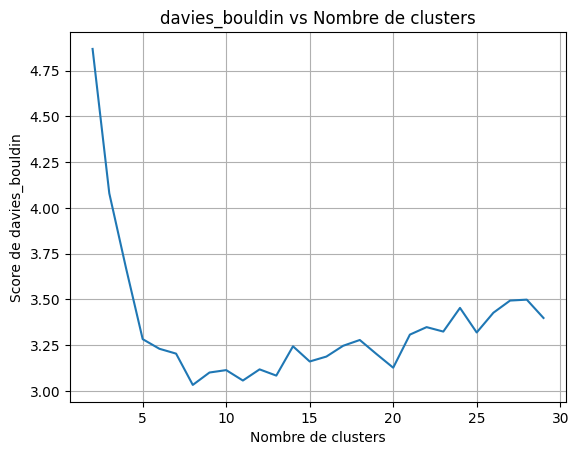

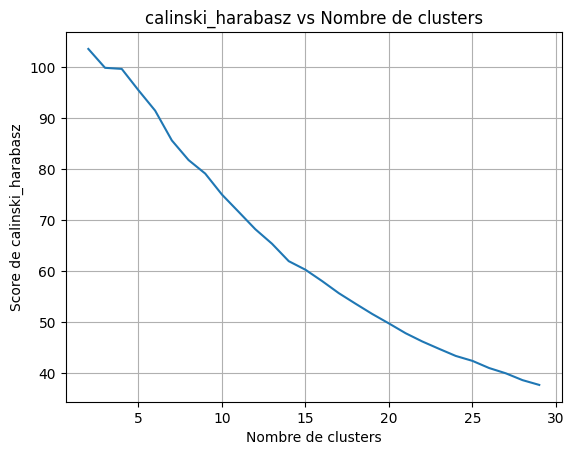

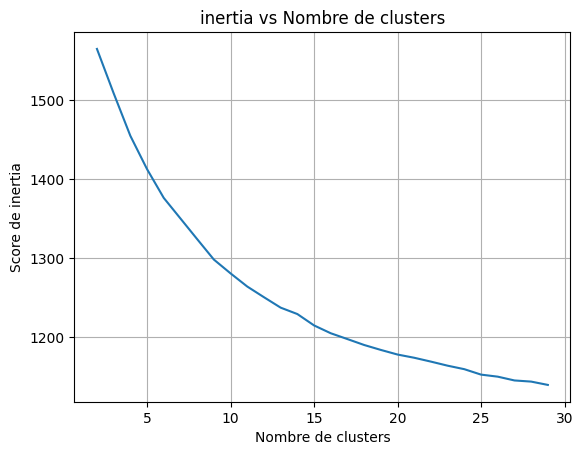

In [39]:
for metric in metrics:
    plt.plot(range(2, 30), metrics[metric], label=metric)
    plt.xlabel('Nombre de clusters')
    plt.ylabel(f'Score de {metric}')
    plt.title(f'{metric} vs Nombre de clusters')
    plt.grid(True)
    plt.show()

In [40]:
# 4. CLUSTERING AVEC K-MEANS (choisir k optimal)
optimal_k = 13  #Par exemple
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
cluster_labels = kmeans.fit_predict(embeddings_reduced)

df['cluster'] = cluster_labels

# 5. ANALYSE DES CLUSTERS
# Statistiques par cluster
cluster_stats = df.groupby('cluster').agg({
    'id': 'count',
    #'source': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'N/A',
    #'date': ['min', 'max']
}).round(2)

---
### Alternative Clustering Methods (For Teammates)

Below are template cells for implementing other clustering algorithms. Uncomment and modify as needed.

**Remember**: All methods should output:
- `cluster_labels`: array of cluster assignments
- `n_clusters`: number of clusters
- Update dataframe: `df['cluster'] = cluster_labels`

In [41]:
# ============================================================================
# OPTION 2: DBSCAN Clustering
# ============================================================================
# Uncomment to use DBSCAN instead of KMeans

# from sklearn.cluster import DBSCAN
#
# # Experiment with eps and min_samples
# dbscan = DBSCAN(eps=0.5, min_samples=5, metric='cosine')
# cluster_labels = dbscan.fit_predict(embeddings_reduced)
#
# # DBSCAN uses -1 for noise points
# n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
# n_noise = list(cluster_labels).count(-1)
#
# print(f"Number of clusters: {n_clusters}")
# print(f"Number of noise points: {n_noise}")
#
# # Update dataframe
# df['cluster'] = cluster_labels
#
# # Note: You may want to filter out noise points (cluster=-1) for analysis

In [42]:
# ============================================================================
# OPTION 3: Hierarchical/Agglomerative Clustering
# ============================================================================
# Uncomment to use Hierarchical clustering

# from sklearn.cluster import AgglomerativeClustering
#
# # Set desired number of clusters
# n_clusters_desired = 13
#
# hierarchical = AgglomerativeClustering(
#     n_clusters=n_clusters_desired,
#     metric='cosine',
#     linkage='average'  # Try: 'ward', 'complete', 'average', 'single'
# )
# cluster_labels = hierarchical.fit_predict(embeddings_reduced)
# n_clusters = n_clusters_desired
#
# print(f"Number of clusters: {n_clusters}")
#
# # Update dataframe
# df['cluster'] = cluster_labels
#
# # Optional: Plot dendrogram for visualization
# # from scipy.cluster.hierarchy import dendrogram, linkage
# # Z = linkage(embeddings_reduced, method='average', metric='cosine')
# # plt.figure(figsize=(10, 7))
# # dendrogram(Z)
# # plt.show()

In [43]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Télécharger les stop words français si nécessaire
nltk.download('stopwords')
english_stop_words = stopwords.words('english')

# Add custom stopwords for resume-specific noise
custom_stopwords = list(english_stop_words) + [
    'company', 'january', 'february', 'march', 'april', 'may', 'june',
    'july', 'august', 'september', 'october', 'november', 'december',
    'present', 'summary', 'experience', 'responsibilities', 'duties',
    'including', 'worked', 'years', 'responsible', 'various', 'multiple',
    'excellent', 'great', 'good', 'provided', 'ensured', 'created'
]

def extract_keywords_by_cluster(texts, labels, n_keywords=10):
    """Extrait les mots-clés TF-IDF par cluster"""
    unique_labels = np.unique(labels)
    keywords_by_cluster = {}

    for label in unique_labels:
        cluster_texts = [texts[i] for i in range(len(texts)) if labels[i] == label]

        if len(cluster_texts) < 2:
            keywords_by_cluster[label] = ["peu_de_documents"]
            continue

        # CRÉER UN NOUVEAU VECTORIZER POUR CHAQUE CLUSTER
        vectorizer = TfidfVectorizer(
            max_features=100,
            stop_words=custom_stopwords,
            ngram_range=(1, 3),  # Unigrams, bigrams and trigrams
            min_df=3,  # Mot doit apparaître dans au moins 3 docs du cluster
            max_df=0.5,  # Éliminer les mots apparaissant dans > 50% des docs
            token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b'  # Au moins 2 lettres
        )

        try:
            tfidf_matrix = vectorizer.fit_transform(cluster_texts)
            feature_names = vectorizer.get_feature_names_out()

            if len(feature_names) == 0:
                keywords_by_cluster[label] = ["aucun_mot"]
                continue

            tfidf_scores = tfidf_matrix.mean(axis=0).A1
            top_indices = tfidf_scores.argsort()[-n_keywords:][::-1]
            top_keywords = [feature_names[i] for i in top_indices]
            keywords_by_cluster[label] = top_keywords

        except Exception as e:
            keywords_by_cluster[label] = [f"erreur: {str(e)[:30]}"]

    return keywords_by_cluster

# Utiliser la colonne 'text' ou 'chunk_text' pour l'extraction
texts = df['text'].fillna('').astype(str).tolist()
keywords_by_cluster = extract_keywords_by_cluster(texts, cluster_labels, n_keywords=8)

print("\nMots-clés par cluster :")
for cluster in sorted(keywords_by_cluster.keys()):
    keywords = keywords_by_cluster[cluster]
    print(f"Cluster {cluster}: {', '.join(keywords)}")

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/khaledbouabdallah/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Mots-clés par cluster :
Cluster 0: merchandise, staff, client, clients, sales associate, marketing, well, policies
Cluster 1: account, accounts, data, customer service, director, strategy, strategies, quality
Cluster 2: sales, healthcare, client, customer service, program, clinical, nursing, research
Cluster 3: graphic, interior, marketing, project, art, customer, graphic designer, clients
Cluster 4: aviation, sales, aircraft, customer service, manager, business, personnel, production
Cluster 5: children, service, grade, academic, customer, reading, english, child
Cluster 6: tax, payroll, ledger, credit, project, general ledger, audit, prepare
Cluster 7: leadership, sales, customer service, candidates, staffing, assistant, processes, clients
Cluster 8: mechanical, manufacturing, site, maintenance, analysis, electrical, building, field
Cluster 9: wellness, customer service, member, equipment, nutrition, student, customers, business
Cluster 10: executive chef, catering, cook, chef name,

In [44]:
# For each cluster, randomly pick 5 sample resumes
np.random.seed(RANDOM_SEED)  # For reproducibility

print("\n" + "="*80)
print("SAMPLE RESUMES BY CLUSTER")
print("="*80)

for cluster_id in sorted(df['cluster'].unique()):
    cluster_df = df[df['cluster'] == cluster_id]
    n_samples = min(10, len(cluster_df))  # Take 3 samples or fewer if cluster is small

    samples = cluster_df.sample(n=n_samples, random_state=RANDOM_SEED)

    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id} - Keywords: {', '.join(keywords_by_cluster[cluster_id])}")
    print(f"Total resumes: {len(cluster_df)}")
    print(f"{'='*80}\n")

    for idx, (_, row) in enumerate(samples.iterrows(), 1):
        # Extract first 400 characters for preview
        text_preview = row['text'][:400].replace('\n', ' ')
        print(f"Sample {idx}:")
        print(f"  Name: {row['name'][:50]}")
        print(f"  Preview: {text_preview}...")
        print()


SAMPLE RESUMES BY CLUSTER

CLUSTER 0 - Keywords: merchandise, staff, client, clients, sales associate, marketing, well, policies
Total resumes: 249

Sample 1:
  Name: SALES ASSOCIATE
  Preview:          SALES ASSOCIATE       Summary      Customer-focused management professional, with successful track record of leading and managing teams . Quality-oriented and proactive in resolving issues with exceptional organizational and communication skills. Self-starter with a positive, can-do attitude who is driven to learn, improve and succeed.       Skills    billing, billing system, budgets, bud...

Sample 2:
  Name: PRODUCTION ASSOCIATE
  Preview:          PRODUCTION ASSOCIATE       Summary    Conclude your application letter by thanking the employer for considering you for the position. Include information on how you will follow-up. Complimentary Close Sincerely, Signature The following application letter template lists the information you need to include in the letter you submit with your 

## Visualization: t-SNE and UMAP Projections

### 📝 IMPORTANT: Cluster Names (Manual Step)

**For Teammates**: The `cluster_names` dictionary below is **manually created** and specific to KMeans with k=13. 

#### 🔄 You MUST Update This for Your Clustering!

When you use a different clustering method or different parameters, you'll get different clusters. Here's how to create meaningful names:

1. **Run the TF-IDF keyword extraction** (cell above) to see top keywords for each cluster
2. **Sample some resumes** from each cluster to understand the theme
3. **Copy the TF-IDF keywords and sample texts** for each cluster
4. **Use ChatGPT/Claude to generate cluster names**:
   ```
   Prompt: "Here are TF-IDF keywords for a cluster of resumes:
   [paste keywords]
   
   Sample resume excerpts:
   [paste 2-3 examples]
   
   Give me a concise, descriptive name for this job cluster (2-4 words)."
   ```
5. **Update the `cluster_names` dictionary** below with your results

**Alternative**: You can also auto-generate names like `f"Cluster {i}: {', '.join(top_3_keywords)}"` but manual names from LLM are usually more interpretable.

**Note**: All visualizations use these names, so they'll adapt to however many clusters you have!

Computing t-SNE projection...
Computing UMAP projection...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


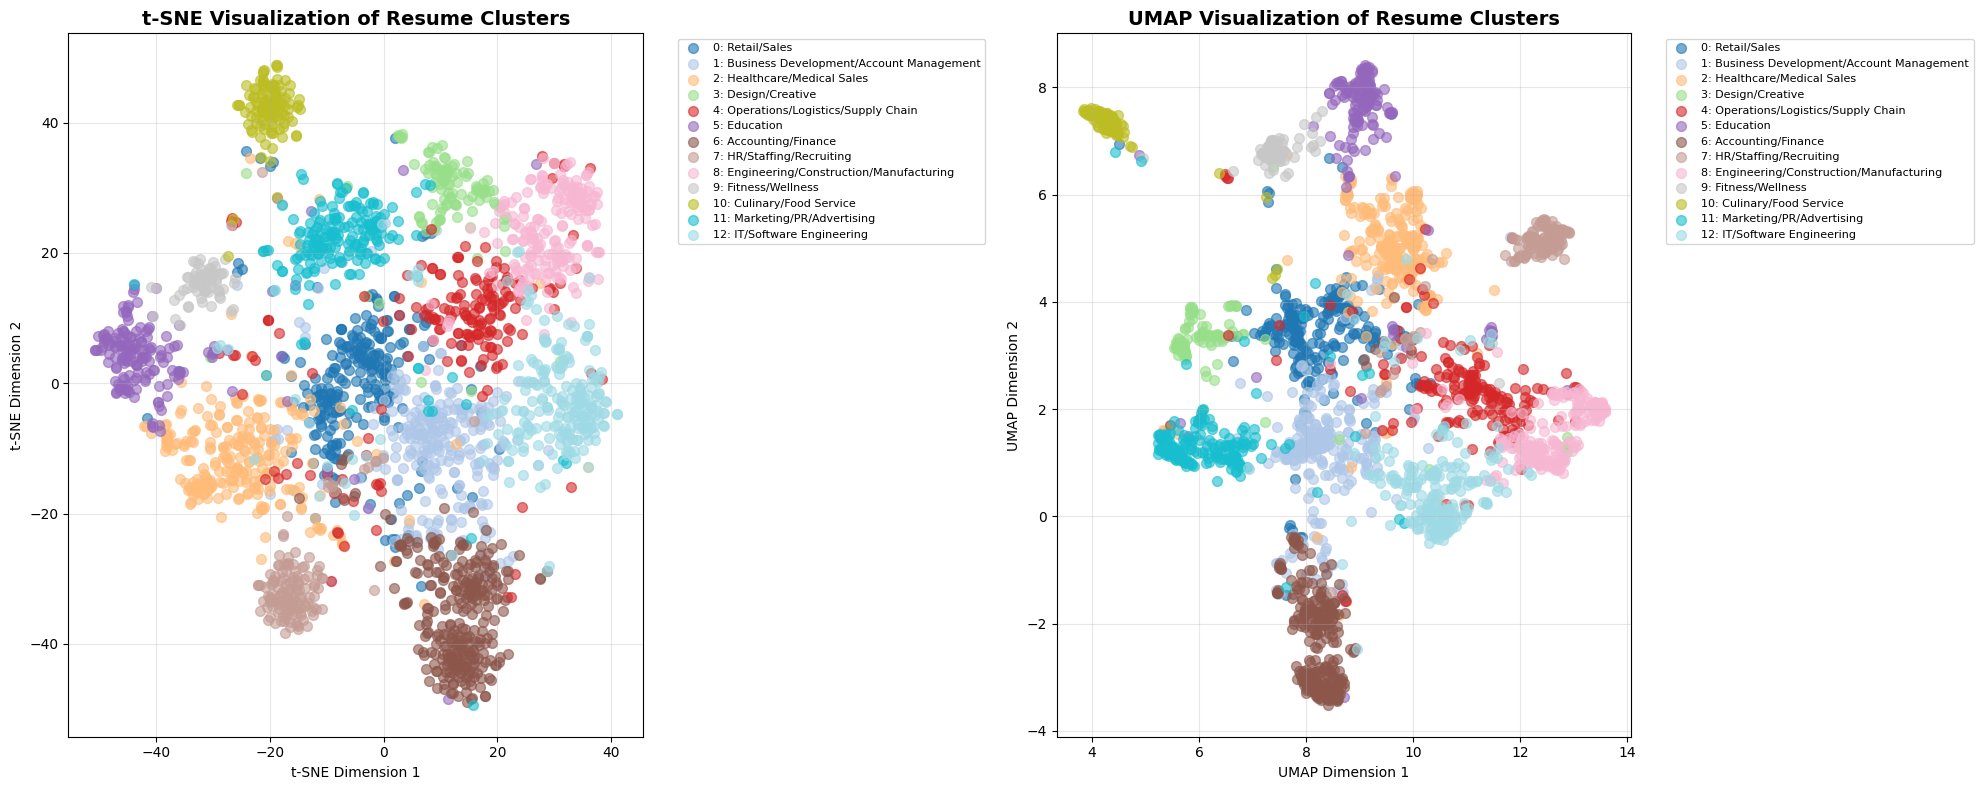

In [45]:
from sklearn.manifold import TSNE
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set up the plot style
plt.style.use('default')

# Define cluster names
cluster_names = {
    0: "Retail/Sales",
    1: "Business Development/Account Management",
    2: "Healthcare/Medical Sales",
    3: "Design/Creative",
    4: "Operations/Logistics/Supply Chain",
    5: "Education",
    6: "Accounting/Finance",
    7: "HR/Staffing/Recruiting",
    8: "Engineering/Construction/Manufacturing",
    9: "Fitness/Wellness",
    10: "Culinary/Food Service",
    11: "Marketing/PR/Advertising",
    12: "IT/Software Engineering"
}

# CHANGE: Create distinct color palette for 13 clusters
n_clusters = len(cluster_names)
colors = plt.cm.tab20(np.linspace(0, 1, n_clusters))  # Using tab20 for distinct colors
# Alternative: colors = sns.color_palette("husl", n_clusters)

# CHANGE: Create color map for each cluster
cluster_colors = {cluster_id: colors[cluster_id] for cluster_id in cluster_names.keys()}

# Create figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. t-SNE visualization
print("Computing t-SNE projection...")
tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=30, n_iter_without_progress=1000)
embeddings_tsne = tsne.fit_transform(embeddings_reduced)

# Plot t-SNE with explicit colors
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    axes[0].scatter(
        embeddings_tsne[mask, 0],
        embeddings_tsne[mask, 1],
        label=f"{cluster_id}: {cluster_names[cluster_id]}",
        color=cluster_colors[cluster_id],  # CHANGE: Use explicit color
        alpha=0.6,
        s=50
    )

axes[0].set_title('t-SNE Visualization of Resume Clusters', fontsize=14, fontweight='bold')
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')
axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[0].grid(True, alpha=0.3)

# 2. UMAP visualization
print("Computing UMAP projection...")
umap_model = umap.UMAP(n_components=2, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1)
embeddings_umap = umap_model.fit_transform(embeddings_reduced)

# Plot UMAP with explicit colors
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    axes[1].scatter(
        embeddings_umap[mask, 0],
        embeddings_umap[mask, 1],
        label=f"{cluster_id}: {cluster_names[cluster_id]}",
        color=cluster_colors[cluster_id],  # CHANGE: Use explicit color
        alpha=0.6,
        s=50
    )

axes[1].set_title('UMAP Visualization of Resume Clusters', fontsize=14, fontweight='bold')
axes[1].set_xlabel('UMAP Dimension 1')
axes[1].set_ylabel('UMAP Dimension 2')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

In [47]:
# ============================================================================
# PROMPT TEMPLATES - Add your own prompt variations here!
# ============================================================================

PROMPT_TEMPLATES = {
    "verbose": [
        "What skills does a {job_title} need?\nProvide a direct answer:",
        "What is the average salary for a {job_title}?\nProvide a direct answer:",
        "What education is required for a {job_title}?\nProvide a direct answer:",
    ],
    "direct": [
        "List {job_title} skills:",
        "{job_title} salary:",
        "{job_title} education requirements:",
    ],
    "structured": [
        "Job: {job_title}\nTask: List required skills\nAnswer:",
        "Job: {job_title}\nTask: State average salary\nAnswer:",
        "Job: {job_title}\nTask: State education requirements\nAnswer:",
    ],
    # Add your custom prompt style here:
    "custom": [
        "What skills does a {job_title} need?",
        "What is the average salary for a {job_title}?",
        "What education is required for a {job_title}?",
    ],
}

# Select which prompt style to use (from PROMPT_TEMPLATES above)
templates = PROMPT_TEMPLATES[PROMPT_STYLE]
print(f"✓ Using '{PROMPT_STYLE}' prompt style")
print(f"  Example: {templates[0].format(job_title='Software Engineer')[:80]}...")

✓ Using 'verbose' prompt style
  Example: What skills does a Software Engineer need?
Provide a direct answer:...


In [48]:
# ============================================================================
# MODEL LOADING - CPU/GPU Compatible
# ============================================================================

print(f"Loading model: {MODEL_NAME}...")

if USE_GPU:
    print("🚀 Loading with GPU optimization (4-bit quantization)...")
    # Create quantization config for GPU
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",  # Normal Float 4 (recommended)
        bnb_4bit_compute_dtype=torch.bfloat16,  # Compute in bf16 for speed
        bnb_4bit_use_double_quant=True,  # Extra memory savings
    )

    # Load model with GPU optimizations
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        quantization_config=quantization_config,
        device_map="auto",
        torch_dtype=torch.bfloat16,  # Better performance on GPU
        low_cpu_mem_usage=True,
    )
else:
    print("💻 Loading with CPU configuration (no quantization, float32)...")
    print("⏳ This may take a while and inference will be slower...")
    # Load model for CPU (no quantization)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        device_map="cpu",
        torch_dtype=torch.float32,  # CPU requires float32
        low_cpu_mem_usage=True,
    )

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Configure tokenizer for batching
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"  # Important for causal LM generation

model.eval()

print(f"✓ Model loaded on device: {model.device}")
print(f"✓ Model dtype: {model.dtype}")
print(f"✓ Batch size: {BATCH_SIZE}")


Loading model: mistralai/Mistral-7B-Instruct-v0.2...
🚀 Loading with GPU optimization (4-bit quantization)...


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

✓ Model loaded on device: cuda:0
✓ Model dtype: torch.bfloat16
✓ Batch size: 32


In [49]:
from tqdm import tqdm
import json
import gc

def generate_questions_with_logits_batched(df, model, tokenizer, templates, cluster_names, batch_size=8):
    """
    Generate questions with batching for much faster GPU utilization.
    Includes proper GPU memory management.

    Returns a list of dictionaries containing:
    - job_name: the job title
    - cluster: cluster ID
    - cluster_name: semantic cluster name
    - question_idx: which question template (0, 1, or 2)
    - question: the full question text
    - generated_answer: the LLM's response
    - token_logits: list of max logit for each generated token
    - avg_confidence: average of token-level confidences
    """
    results = []

    # Prepare all questions upfront with direct prompting
    all_data = []
    for idx, row in df.iterrows():
        job_name = row['name']
        cluster_id = row['cluster']
        cluster_name = cluster_names.get(cluster_id, f"Cluster {cluster_id}")

        for q_idx, template in enumerate(templates):
            base_question = template.format(job_title=job_name)

            # Use Mistral's instruction format to prevent echoing
            # [INST] tells model this is an instruction, [/INST] is where it should respond
            question = f"[INST] {base_question} [/INST]"

            all_data.append({
                'job_name': job_name,
                'cluster': cluster_id,
                'cluster_name': cluster_name,
                'question_idx': q_idx,
                'question': base_question,  # Store original question
                'prompt': question  # Store formatted prompt
            })
    print(f"Prepared {len(all_data)} questions to process in batches of {batch_size}")

    # Clear GPU memory before starting (GPU only)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

    # Process in batches
    for i in tqdm(range(0, len(all_data), batch_size), desc="Generating answers (batched)"):
        batch = all_data[i:i + batch_size]
        prompts = [item['prompt'] for item in batch]  # Use formatted prompts

        # Tokenize batch with padding
        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
        ).to(model.device)

        # Generate for batch
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                output_scores=True,
                return_dict_in_generate=True,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id
            )

        # Process each item in batch
        for j, item in enumerate(batch):
            # Extract token-level logits for this sample
            token_logits = []
            for score in outputs.scores:
                max_prob = torch.softmax(score[j], dim=-1).max().item()
                token_logits.append(max_prob)

            avg_confidence = sum(token_logits) / len(token_logits) if token_logits else 0.0

            # FIXED: Skip the ENTIRE input sequence (padding + tokens)
            # outputs.sequences[j] = [all input tokens including padding] + [generated tokens]
            # inputs.input_ids[j] = [all input tokens including padding]
            input_ids = inputs.input_ids[j]

            # Use the FULL length of input (padding + actual tokens) to find where generation starts
            input_length = len(input_ids)

            # Extract ONLY the newly generated tokens
            generated_only = outputs.sequences[j][input_length:]
            generated_answer = tokenizer.decode(generated_only, skip_special_tokens=True)

            # Strip common unwanted prefixes that models often add
            unwanted_prefixes = ['Answer:', 'answer:', '] Answer:', ']', ': ', 'A: ', '\n']
            for prefix in unwanted_prefixes:
                if generated_answer.startswith(prefix):
                    generated_answer = generated_answer[len(prefix):].lstrip()

            results.append({
                **item,
                'generated_answer': generated_answer.strip(),
                'token_logits': token_logits,
                'avg_confidence': avg_confidence,
                'num_tokens': len(token_logits)
            })
# Clear any existing GPU memory first
        # Clear GPU memory after each batch (GPU only)
        del inputs, outputs
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return results

# Clear any existing GPU memory first (GPU only)
if torch.cuda.is_available():
    print("Clearing GPU memory...")
    torch.cuda.empty_cache()
gc.collect()

# Check current GPU memory
if torch.cuda.is_available():
    print(f"GPU Memory before generation:")
    print(f"  Allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    print(f"  Reserved: {torch.cuda.memory_reserved() / 1e9:.2f} GB")
    print()

# Select data based on USE_SAMPLE configuration
if USE_SAMPLE:
    print(f"⚠️  SAMPLE MODE: Using only {SAMPLE_SIZE} samples for testing")
    df_to_process = df.iloc[:SAMPLE_SIZE].copy()

    # Show which clusters are in the sample
    sample_clusters = sorted(df_to_process['cluster'].unique())
    print(f"   Sample contains {len(sample_clusters)} clusters: {sample_clusters}")

    # Warn if some clusters are missing
    all_clusters = sorted(cluster_names.keys())
    missing_clusters = [c for c in all_clusters if c not in sample_clusters]
    if missing_clusters:
        print(f"   Note: These clusters won't be in results: {missing_clusters}")
else:
    print(f"📊 FULL MODE: Processing all {len(df)} samples")
    df_to_process = df.copy()

print(f"Processing {len(df_to_process)} jobs × {len(templates)} questions = {len(df_to_process) * len(templates)} total generations")
results = generate_questions_with_logits_batched(df_to_process, model, tokenizer, templates, cluster_names, batch_size=BATCH_SIZE)


print(f"  Reserved: {torch.cuda.memory_reserved() / 1e9:.2f} GB")

# Final memory status    print(f"  Allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

if torch.cuda.is_available():    print(f"\nGPU Memory after generation:")

Clearing GPU memory...
GPU Memory before generation:
  Allocated: 4.14 GB
  Reserved: 8.41 GB

📊 FULL MODE: Processing all 2484 samples
Processing 2484 jobs × 3 questions = 7452 total generations
Prepared 7452 questions to process in batches of 32


Generating answers (batched): 100%|██████████| 233/233 [49:56<00:00, 12.86s/it]

  Reserved: 8.77 GB

GPU Memory after generation:


In [50]:
# Convert results to DataFrame for easier analysis
results_df = pd.DataFrame(results)

# Display first few rows
print("\nResults DataFrame:")
print(results_df.head(10))
print(f"\nShape: {results_df.shape}")
print(f"\nColumns: {results_df.columns.tolist()}")
print(f"\nData types:\n{results_df.dtypes}")


Results DataFrame:
                                            job_name  cluster  \
0  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        7   
1  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        7   
2  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        7   
3                    HR SPECIALIST, US HR OPERATIONS        7   
4                    HR SPECIALIST, US HR OPERATIONS        7   
5                    HR SPECIALIST, US HR OPERATIONS        7   
6                                        HR DIRECTOR        7   
7                                        HR DIRECTOR        7   
8                                        HR DIRECTOR        7   
9                                      HR SPECIALIST        0   

             cluster_name  question_idx  \
0  HR/Staffing/Recruiting             0   
1  HR/Staffing/Recruiting             1   
2  HR/Staffing/Recruiting             2   
3  HR/Staffing/Recruiting             0   
4  HR/Staffing/Recruiting             1   
5  HR/

In [51]:
# Save results to CSV (token_logits as JSON string)
output_file = '../data/llm_generation_results.csv'

# Create a copy for saving (convert list to JSON string for CSV compatibility)
results_df_to_save = results_df.copy()
results_df_to_save['token_logits'] = results_df_to_save['token_logits'].apply(json.dumps)

results_df_to_save.to_csv(output_file, index=False)
print(f"✓ Results saved to {output_file}")

# Also save as pickle to preserve list structure
pickle_file = '../data/llm_generation_results.pkl'
results_df.to_pickle(pickle_file)
print(f"✓ Results saved to {pickle_file} (with native Python lists)")

✓ Results saved to ../data/llm_generation_results.csv
✓ Results saved to ../data/llm_generation_results.pkl (with native Python lists)


In [52]:
# Statistical summary by cluster
print("\n" + "="*80)
print("CONFIDENCE STATISTICS BY CLUSTER")
print("="*80)

cluster_summary = results_df.groupby('cluster').agg({
    'avg_confidence': ['mean', 'std', 'min', 'max', 'count'],
    'num_tokens': 'mean'
}).round(4)

cluster_summary.columns = ['_'.join(col).strip() for col in cluster_summary.columns.values]
cluster_summary = cluster_summary.sort_values('avg_confidence_mean', ascending=False)

# Add cluster names (with fallback for missing clusters)
cluster_summary['cluster_name'] = cluster_summary.index.map(
    lambda x: cluster_names.get(x, f"Cluster {x}")
)

print(cluster_summary)

# Statistical summary by question type
print("\n" + "="*80)
print("CONFIDENCE STATISTICS BY QUESTION TYPE")
print("="*80)

question_summary = results_df.groupby('question_idx').agg({
    'avg_confidence': ['mean', 'std', 'min', 'max', 'count'],
    'num_tokens': 'mean'
}).round(4)

question_summary.columns = ['_'.join(col).strip() for col in question_summary.columns.values]
question_summary['question_template'] = [templates[i] for i in question_summary.index]

print(question_summary)


CONFIDENCE STATISTICS BY CLUSTER
         avg_confidence_mean  avg_confidence_std  avg_confidence_min  \
cluster                                                                
3                     0.8478              0.0565              0.5552   
4                     0.8450              0.0707              0.5306   
7                     0.8411              0.0761              0.5116   
5                     0.8402              0.0715              0.5523   
0                     0.8401              0.0702              0.4673   
6                     0.8351              0.0828              0.4598   
9                     0.8345              0.0733              0.5573   
8                     0.8324              0.0792              0.5315   
2                     0.8293              0.0822              0.4280   
1                     0.8207              0.0913              0.4977   
10                    0.8186              0.0807              0.4728   
11                    0.8164  

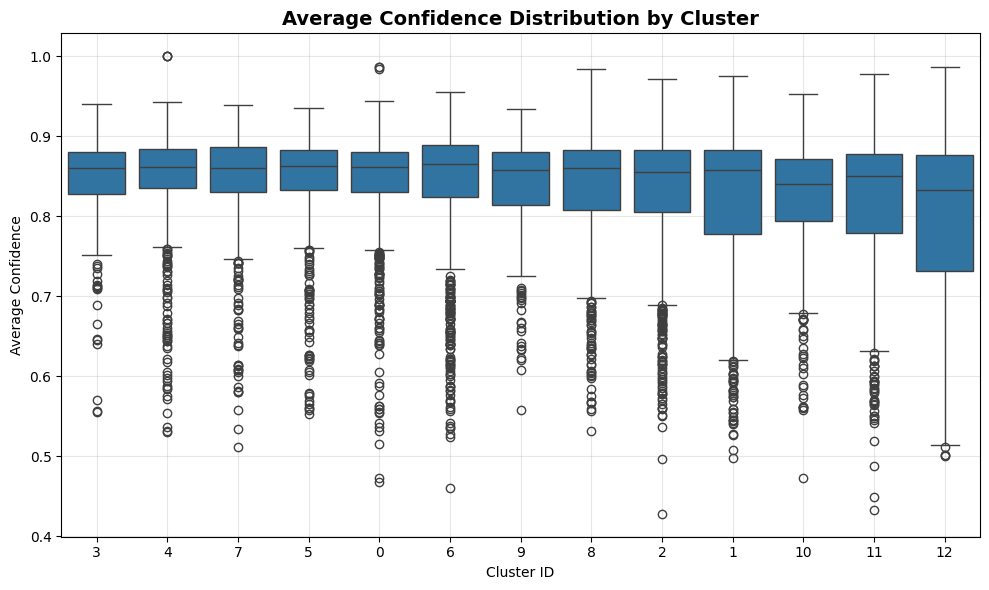

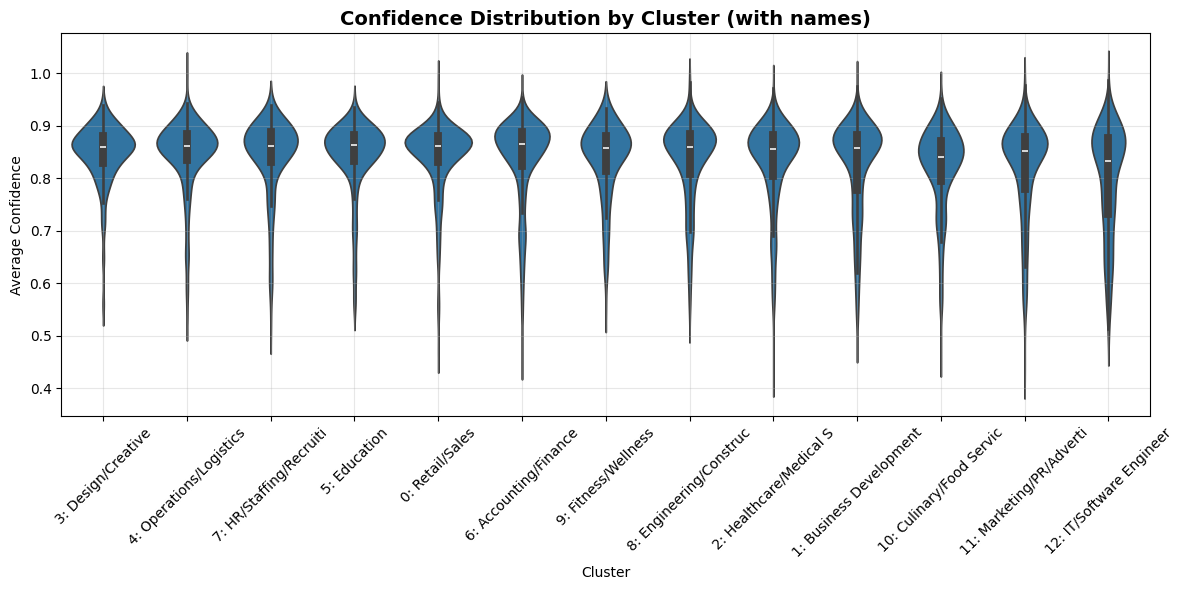

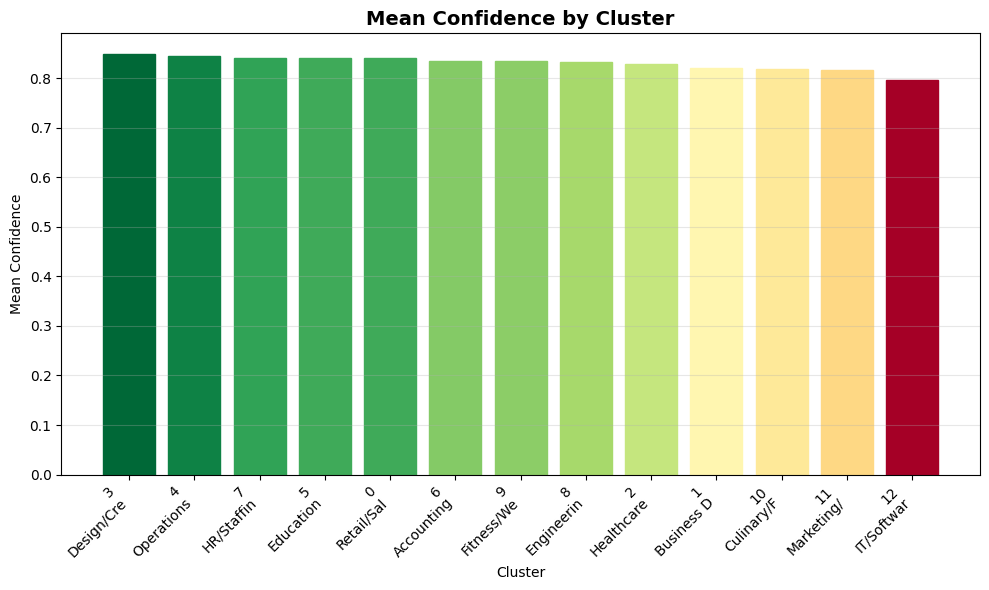

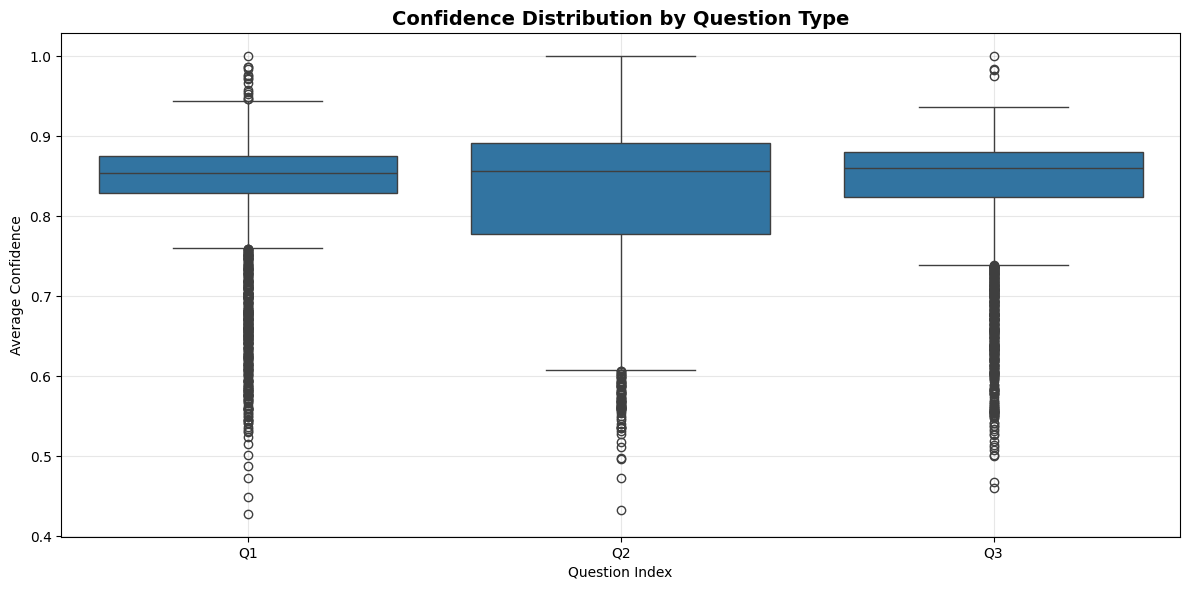

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Box plot: Confidence by Cluster
plt.figure(figsize=(10, 6))
cluster_order = results_df.groupby('cluster')['avg_confidence'].mean().sort_values(ascending=False).index
sns.boxplot(data=results_df, x='cluster', y='avg_confidence', order=cluster_order)
plt.title('Average Confidence Distribution by Cluster', fontsize=14, fontweight='bold')
plt.xlabel('Cluster ID')
plt.ylabel('Average Confidence')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../data/confidence_by_cluster.png', dpi=300)
plt.show()


# 2. Violin plot: Confidence by Cluster with cluster names
results_df_plot = results_df.copy()
results_df_plot['cluster_label'] = results_df_plot.apply(
    lambda row: f"{row['cluster']}: {cluster_names.get(row['cluster'], 'Unknown')[:20]}", axis=1
)
cluster_label_order = results_df_plot.groupby('cluster_label')['avg_confidence'].mean().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.violinplot(data=results_df_plot, x='cluster_label', y='avg_confidence', order=cluster_label_order)
plt.title('Confidence Distribution by Cluster (with names)', fontsize=14, fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('Average Confidence')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../data/confidence_violin_by_cluster.png', dpi=300)
plt.show()


# 3. Bar plot: Mean Confidence by Cluster
cluster_means = results_df.groupby('cluster')['avg_confidence'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
bars = plt.bar(range(len(cluster_means)), cluster_means.values)
plt.xticks(range(len(cluster_means)), [f"{c}\n{cluster_names.get(c, f'C{c}')[:10]}" for c in cluster_means.index], rotation=45, ha='right')
plt.title('Mean Confidence by Cluster', fontsize=14, fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('Mean Confidence')
plt.grid(True, alpha=0.3, axis='y')

# Color bars by value
colors = plt.cm.RdYlGn([(v - cluster_means.min()) / (cluster_means.max() - cluster_means.min()) for v in cluster_means.values])
for bar, color in zip(bars, colors):
    bar.set_color(color)

plt.tight_layout()
plt.savefig('../data/mean_confidence_by_cluster.png', dpi=300)
plt.show()


# 4. Box plot: Confidence by Question Type
plt.figure(figsize=(12, 6))
results_df_plot['question_label'] = results_df_plot['question_idx'].map(
    {i: f"Q{i+1}: {templates[i][:30]}..." for i in range(len(templates))}
)
sns.boxplot(data=results_df_plot, x='question_idx', y='avg_confidence')
plt.title('Confidence Distribution by Question Type', fontsize=14, fontweight='bold')
plt.xlabel('Question Index')
plt.ylabel('Average Confidence')
plt.xticks(range(len(templates)), [f"Q{i+1}" for i in range(len(templates))])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()




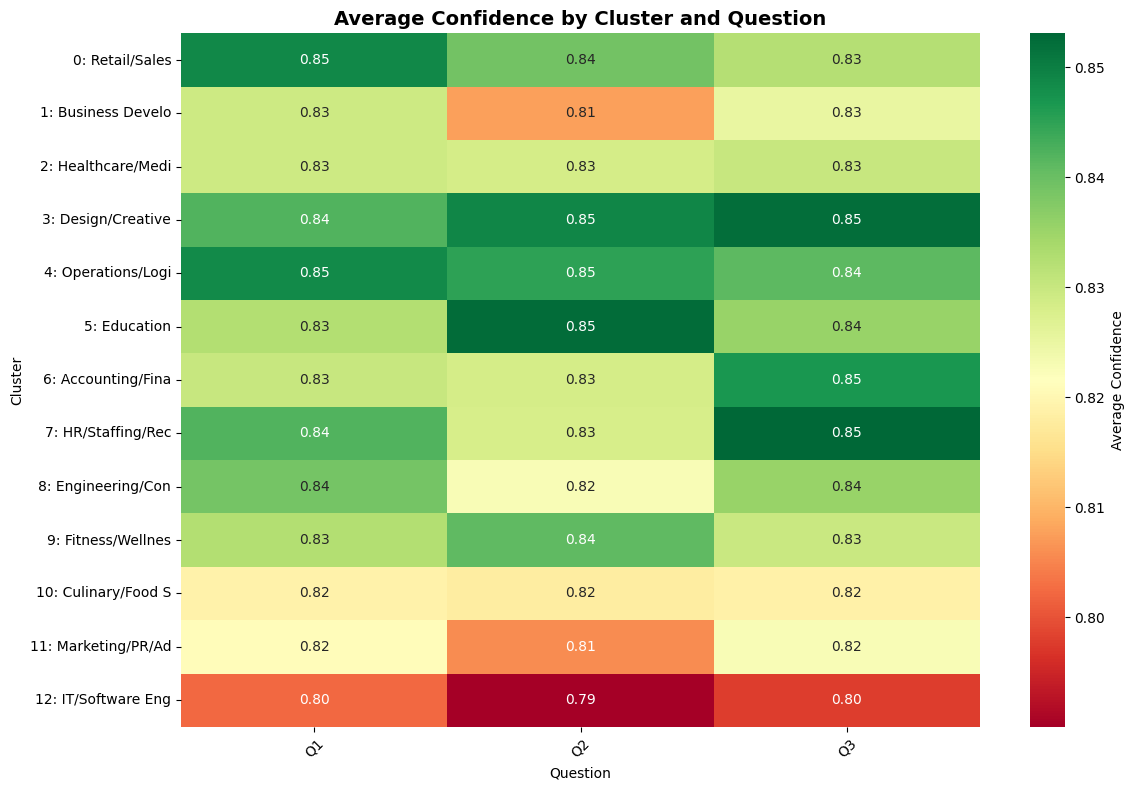

✓ Heatmap saved to ../data/confidence_heatmap.png


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Compute pivot table: rows = clusters, columns = questions, values = average confidence
heatmap_data = results_df.pivot_table(
    index='cluster',
    columns='question_idx',
    values='avg_confidence',
    aggfunc='mean'
)

# Optionally, add cluster names for rows
heatmap_data.index = [f"{c}: {cluster_names.get(c, 'Unknown')[:15]}" for c in heatmap_data.index]

# Optionally, add question labels for columns
heatmap_data.columns = [f"Q{i+1}" for i in heatmap_data.columns]

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='RdYlGn', cbar_kws={'label': 'Average Confidence'})
plt.title('Average Confidence by Cluster and Question', fontsize=14, fontweight='bold')
plt.xlabel('Question')
plt.ylabel('Cluster')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('../data/confidence_heatmap.png', dpi=300)
plt.show()

print("✓ Heatmap saved to ../data/confidence_heatmap.png")


In [55]:
import pandas as pd
import numpy as np
from collections import Counter, defaultdict
import re
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming results_df is already in memory

# ============================================================================
# ANALYSIS 1: VOCABULARY ANALYSIS
# ============================================================================
print("="*80)
print("ANALYSIS 1: VOCABULARY DIVERSITY")
print("="*80)

def tokenize_answer(text):
    """Simple word tokenization"""
    return re.findall(r'\b[a-zA-Z]+\b', text.lower())

vocab_stats = []
for cluster_name in results_df['cluster_name'].unique():
    cluster_data = results_df[results_df['cluster_name'] == cluster_name]

    all_tokens = []
    for answer in cluster_data['generated_answer']:
        all_tokens.extend(tokenize_answer(answer))

    unique_words = len(set(all_tokens))
    total_words = len(all_tokens)
    type_token_ratio = unique_words / total_words if total_words > 0 else 0
    avg_conf = cluster_data['avg_confidence'].mean()

    vocab_stats.append({
        'cluster_name': cluster_name,
        'unique_words': unique_words,
        'total_words': total_words,
        'type_token_ratio': type_token_ratio,
        'avg_confidence': avg_conf
    })

vocab_df = pd.DataFrame(vocab_stats).sort_values('avg_confidence', ascending=False)
print(vocab_df.to_string(index=False))

# Correlation
corr_unique, p_unique = pearsonr(vocab_df['unique_words'], vocab_df['avg_confidence'])
corr_ttr, p_ttr = pearsonr(vocab_df['type_token_ratio'], vocab_df['avg_confidence'])
print(f"\nCorrelation (unique_words vs confidence): r={corr_unique:.3f}, p={p_unique:.3f}")
print(f"Correlation (type_token_ratio vs confidence): r={corr_ttr:.3f}, p={p_ttr:.3f}")

# ============================================================================
# ANALYSIS 2: FILLER/HEDGE WORD FREQUENCY
# ============================================================================
print("\n" + "="*80)
print("ANALYSIS 2: FILLER & HEDGE WORDS")
print("="*80)

hedge_words = [
    'typically', 'often', 'usually', 'generally', 'may', 'might',
    'could', 'sometimes', 'possibly', 'perhaps', 'probably', 'likely',
    'various', 'several', 'many', 'some', 'most'
]

filler_phrases = [
    'in order to', 'it is important', 'it is essential', 'as well as',
    'in addition', 'for example', 'such as', 'in fact', 'of course'
]

hedge_stats = []
for cluster_name in results_df['cluster_name'].unique():
    cluster_data = results_df[results_df['cluster_name'] == cluster_name]

    total_hedge_count = 0
    total_filler_count = 0
    total_words = 0

    for answer in cluster_data['generated_answer']:
        text_lower = answer.lower()
        tokens = tokenize_answer(answer)
        total_words += len(tokens)

        # Count hedge words
        for word in hedge_words:
            total_hedge_count += text_lower.count(f' {word} ') + text_lower.count(f' {word},') + text_lower.count(f' {word}.')

        # Count filler phrases
        for phrase in filler_phrases:
            total_filler_count += text_lower.count(phrase)

    hedge_rate = (total_hedge_count / total_words * 100) if total_words > 0 else 0
    filler_rate = (total_filler_count / total_words * 100) if total_words > 0 else 0
    avg_conf = cluster_data['avg_confidence'].mean()

    hedge_stats.append({
        'cluster_name': cluster_name,
        'hedge_rate_%': hedge_rate,
        'filler_rate_%': filler_rate,
        'total_rate_%': hedge_rate + filler_rate,
        'avg_confidence': avg_conf
    })

hedge_df = pd.DataFrame(hedge_stats).sort_values('avg_confidence', ascending=False)
print(hedge_df.to_string(index=False))

corr_hedge, p_hedge = pearsonr(hedge_df['hedge_rate_%'], hedge_df['avg_confidence'])
corr_total, p_total = pearsonr(hedge_df['total_rate_%'], hedge_df['avg_confidence'])
print(f"\nCorrelation (hedge_rate vs confidence): r={corr_hedge:.3f}, p={p_hedge:.3f}")
print(f"Correlation (total_rate vs confidence): r={corr_total:.3f}, p={p_total:.3f}")

# ============================================================================
# ANALYSIS 3: COMMON WORD DOMINANCE
# ============================================================================
print("\n" + "="*80)
print("ANALYSIS 3: COMMON WORD DOMINANCE")
print("="*80)

# Top 1000 most common English words (approximate list)
common_words = set([
    'the', 'be', 'to', 'of', 'and', 'a', 'in', 'that', 'have', 'i', 'it', 'for', 'not',
    'on', 'with', 'he', 'as', 'you', 'do', 'at', 'this', 'but', 'his', 'by', 'from',
    'they', 'we', 'say', 'her', 'she', 'or', 'an', 'will', 'my', 'one', 'all', 'would',
    'there', 'their', 'what', 'so', 'up', 'out', 'if', 'about', 'who', 'get', 'which',
    'go', 'me', 'when', 'make', 'can', 'like', 'time', 'no', 'just', 'him', 'know',
    'take', 'people', 'into', 'year', 'your', 'good', 'some', 'could', 'them', 'see',
    'other', 'than', 'then', 'now', 'look', 'only', 'come', 'its', 'over', 'think',
    'also', 'back', 'after', 'use', 'two', 'how', 'our', 'work', 'first', 'well',
    'way', 'even', 'new', 'want', 'because', 'any', 'these', 'give', 'day', 'most',
    'us', 'is', 'are', 'was', 'been', 'has', 'had', 'may', 'should', 'such', 'must',
    'through', 'including', 'various', 'many', 'different', 'both', 'each', 'more',
    'experience', 'skills', 'ability', 'strong', 'required', 'working', 'support',
    'including', 'such', 'well', 'ensure', 'provide', 'develop', 'manage', 'ability'
])

common_word_stats = []
for cluster_name in results_df['cluster_name'].unique():
    cluster_data = results_df[results_df['cluster_name'] == cluster_name]

    common_word_count = 0
    total_words = 0

    for answer in cluster_data['generated_answer']:
        tokens = tokenize_answer(answer)
        total_words += len(tokens)
        common_word_count += sum(1 for token in tokens if token in common_words)

    common_word_pct = (common_word_count / total_words * 100) if total_words > 0 else 0
    avg_conf = cluster_data['avg_confidence'].mean()

    common_word_stats.append({
        'cluster_name': cluster_name,
        'common_word_%': common_word_pct,
        'avg_confidence': avg_conf
    })

common_df = pd.DataFrame(common_word_stats).sort_values('avg_confidence', ascending=False)
print(common_df.to_string(index=False))

corr_common, p_common = pearsonr(common_df['common_word_%'], common_df['avg_confidence'])
print(f"\nCorrelation (common_word_% vs confidence): r={corr_common:.3f}, p={p_common:.3f}")

# ============================================================================
# ANALYSIS 4: TEMPLATE PATTERN DETECTION
# ============================================================================
print("\n" + "="*80)
print("ANALYSIS 4: TEMPLATE PATTERNS (First 10 tokens)")
print("="*80)

template_stats = []
for cluster_name in results_df['cluster_name'].unique():
    cluster_data = results_df[results_df['cluster_name'] == cluster_name]

    first_10_patterns = []
    for answer in cluster_data['generated_answer']:
        tokens = tokenize_answer(answer)
        if len(tokens) >= 10:
            pattern = ' '.join(tokens[:10])
            first_10_patterns.append(pattern)

    # Count pattern frequency
    pattern_counts = Counter(first_10_patterns)
    total_answers = len(first_10_patterns)

    if total_answers > 0:
        most_common_pattern = pattern_counts.most_common(1)[0]
        repetition_rate = most_common_pattern[1] / total_answers * 100
        unique_patterns = len(pattern_counts)
    else:
        repetition_rate = 0
        unique_patterns = 0

    avg_conf = cluster_data['avg_confidence'].mean()

    template_stats.append({
        'cluster_name': cluster_name,
        'unique_patterns': unique_patterns,
        'total_answers': total_answers,
        'top_pattern_rate_%': repetition_rate,
        'avg_confidence': avg_conf
    })

template_df = pd.DataFrame(template_stats).sort_values('avg_confidence', ascending=False)
print(template_df.to_string(index=False))

corr_pattern, p_pattern = pearsonr(template_df['top_pattern_rate_%'], template_df['avg_confidence'])
print(f"\nCorrelation (top_pattern_rate vs confidence): r={corr_pattern:.3f}, p={p_pattern:.3f}")

# Show top pattern for highest and lowest confidence clusters
print("\n--- Top patterns for extreme clusters ---")
for cluster in [template_df.iloc[0]['cluster_name'], template_df.iloc[-1]['cluster_name']]:
    cluster_data = results_df[results_df['cluster_name'] == cluster]
    patterns = []
    for answer in cluster_data['generated_answer']:
        tokens = tokenize_answer(answer)
        if len(tokens) >= 10:
            patterns.append(' '.join(tokens[:10]))
    pattern_counts = Counter(patterns)
    print(f"\n{cluster} (conf={results_df[results_df['cluster_name']==cluster]['avg_confidence'].mean():.3f}):")
    for pattern, count in pattern_counts.most_common(3):
        print(f"  [{count:3d}x] {pattern}")

# ============================================================================
# ANALYSIS 5: TOKEN POSITION CONFIDENCE
# ============================================================================
print("\n" + "="*80)
print("ANALYSIS 5: TOKEN POSITION ANALYSIS")
print("="*80)

# Calculate average confidence at each token position for each cluster
position_data = defaultdict(lambda: defaultdict(list))

for _, row in results_df.iterrows():
    cluster_name = row['cluster_name']
    token_logits = row['token_logits']

    for pos, logit in enumerate(token_logits):
        if pos < 100:  # Ensure we're within 100 tokens
            position_data[cluster_name][pos].append(logit)

# Calculate means
position_means = {}
for cluster_name in position_data:
    positions = []
    means = []
    for pos in sorted(position_data[cluster_name].keys()):
        positions.append(pos)
        means.append(np.mean(position_data[cluster_name][pos]))
    position_means[cluster_name] = (positions, means)

# Calculate variance across positions for each cluster
position_stats = []
for cluster_name in results_df['cluster_name'].unique():
    if cluster_name in position_means:
        positions, means = position_means[cluster_name]
        confidence_variance = np.var(means)
        confidence_std = np.std(means)
        early_confidence = np.mean(means[:20])  # First 20 tokens
        late_confidence = np.mean(means[-20:])  # Last 20 tokens
        confidence_drop = early_confidence - late_confidence

        avg_conf = results_df[results_df['cluster_name'] == cluster_name]['avg_confidence'].mean()

        position_stats.append({
            'cluster_name': cluster_name,
            'conf_variance': confidence_variance,
            'conf_std': confidence_std,
            'early_conf': early_confidence,
            'late_conf': late_confidence,
            'conf_drop': confidence_drop,
            'avg_confidence': avg_conf
        })

position_df = pd.DataFrame(position_stats).sort_values('avg_confidence', ascending=False)
print(position_df.to_string(index=False))

corr_variance, p_variance = pearsonr(position_df['conf_variance'], position_df['avg_confidence'])
corr_drop, p_drop = pearsonr(position_df['conf_drop'], position_df['avg_confidence'])
print(f"\nCorrelation (conf_variance vs confidence): r={corr_variance:.3f}, p={p_variance:.3f}")
print(f"Correlation (conf_drop vs confidence): r={corr_drop:.3f}, p={p_drop:.3f}")

# ============================================================================
# ANALYSIS 6: DOMAIN-SPECIFIC VOCABULARY
# ============================================================================
print("\n" + "="*80)
print("ANALYSIS 6: DOMAIN-SPECIFIC VOCABULARY")
print("="*80)

# Build vocabulary per cluster
cluster_vocabularies = {}
for cluster_name in results_df['cluster_name'].unique():
    cluster_data = results_df[results_df['cluster_name'] == cluster_name]
    vocab = set()
    for answer in cluster_data['generated_answer']:
        tokens = tokenize_answer(answer)
        vocab.update(tokens)
    cluster_vocabularies[cluster_name] = vocab

# Find words that appear in <3 clusters (domain-specific)
word_cluster_count = defaultdict(set)
for cluster_name, vocab in cluster_vocabularies.items():
    for word in vocab:
        word_cluster_count[word].add(cluster_name)

domain_specific_words = {word for word, clusters in word_cluster_count.items()
                         if len(clusters) <= 3 and len(word) > 3}  # At least 4 chars

# Calculate domain-specific density per cluster
domain_stats = []
for cluster_name in results_df['cluster_name'].unique():
    cluster_data = results_df[results_df['cluster_name'] == cluster_name]

    domain_word_count = 0
    total_words = 0

    for answer in cluster_data['generated_answer']:
        tokens = tokenize_answer(answer)
        total_words += len(tokens)
        domain_word_count += sum(1 for token in tokens if token in domain_specific_words)

    domain_density = (domain_word_count / total_words * 100) if total_words > 0 else 0
    avg_conf = cluster_data['avg_confidence'].mean()

    # Get top domain-specific words for this cluster
    cluster_domain_words = []
    for answer in cluster_data['generated_answer']:
        tokens = tokenize_answer(answer)
        cluster_domain_words.extend([t for t in tokens if t in domain_specific_words])

    top_domain_words = [word for word, count in Counter(cluster_domain_words).most_common(5)]

    domain_stats.append({
        'cluster_name': cluster_name,
        'domain_density_%': domain_density,
        'top_domain_words': ', '.join(top_domain_words[:5]) if top_domain_words else 'N/A',
        'avg_confidence': avg_conf
    })

domain_df = pd.DataFrame(domain_stats).sort_values('avg_confidence', ascending=False)
print(domain_df.to_string(index=False))

corr_domain, p_domain = pearsonr(domain_df['domain_density_%'], domain_df['avg_confidence'])
print(f"\nCorrelation (domain_density vs confidence): r={corr_domain:.3f}, p={p_domain:.3f}")

# ============================================================================
# SUMMARY STATISTICS
# ============================================================================
print("\n" + "="*80)
print("SUMMARY: ALL CORRELATIONS WITH AVG_CONFIDENCE")
print("="*80)

correlations = [
    ('Unique Words', corr_unique, p_unique),
    ('Type-Token Ratio', corr_ttr, p_ttr),
    ('Hedge Word Rate', corr_hedge, p_hedge),
    ('Total Filler Rate', corr_total, p_total),
    ('Common Word %', corr_common, p_common),
    ('Top Pattern Rate', corr_pattern, p_pattern),
    ('Confidence Variance', corr_variance, p_variance),
    ('Confidence Drop', corr_drop, p_drop),
    ('Domain Density', corr_domain, p_domain),
]

print(f"{'Metric':<25} {'Correlation':>12} {'P-value':>10} {'Significance':>15}")
print("-" * 65)
for metric, corr, p in correlations:
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f"{metric:<25} {corr:>12.3f} {p:>10.4f} {sig:>15}")

print("\n*** p<0.001, ** p<0.01, * p<0.05, ns = not significant")

ANALYSIS 1: VOCABULARY DIVERSITY
                           cluster_name  unique_words  total_words  type_token_ratio  avg_confidence
                        Design/Creative          1530        21335          0.071713        0.847791
      Operations/Logistics/Supply Chain          2523        37250          0.067732        0.844957
                 HR/Staffing/Recruiting          1169        25325          0.046160        0.841053
                              Education          1863        34582          0.053872        0.840172
                           Retail/Sales          2274        48772          0.046625        0.840072
                     Accounting/Finance          1933        56447          0.034245        0.835116
                       Fitness/Wellness          1429        13989          0.102152        0.834493
 Engineering/Construction/Manufacturing          2195        37980          0.057794        0.832382
               Healthcare/Medical Sales          2974     

In [56]:
results_df.iloc[0]

job_name            HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...
cluster                                                             7
cluster_name                                   HR/Staffing/Recruiting
question_idx                                                        0
question            What skills does a HR ADMINISTRATOR/MARKETING ...
prompt              [INST] What skills does a HR ADMINISTRATOR/MAR...
generated_answer    A HR Administrator typically needs the followi...
token_logits        [0.9220365881919861, 0.9932265877723694, 0.999...
avg_confidence                                               0.859591
num_tokens                                                        100
Name: 0, dtype: object

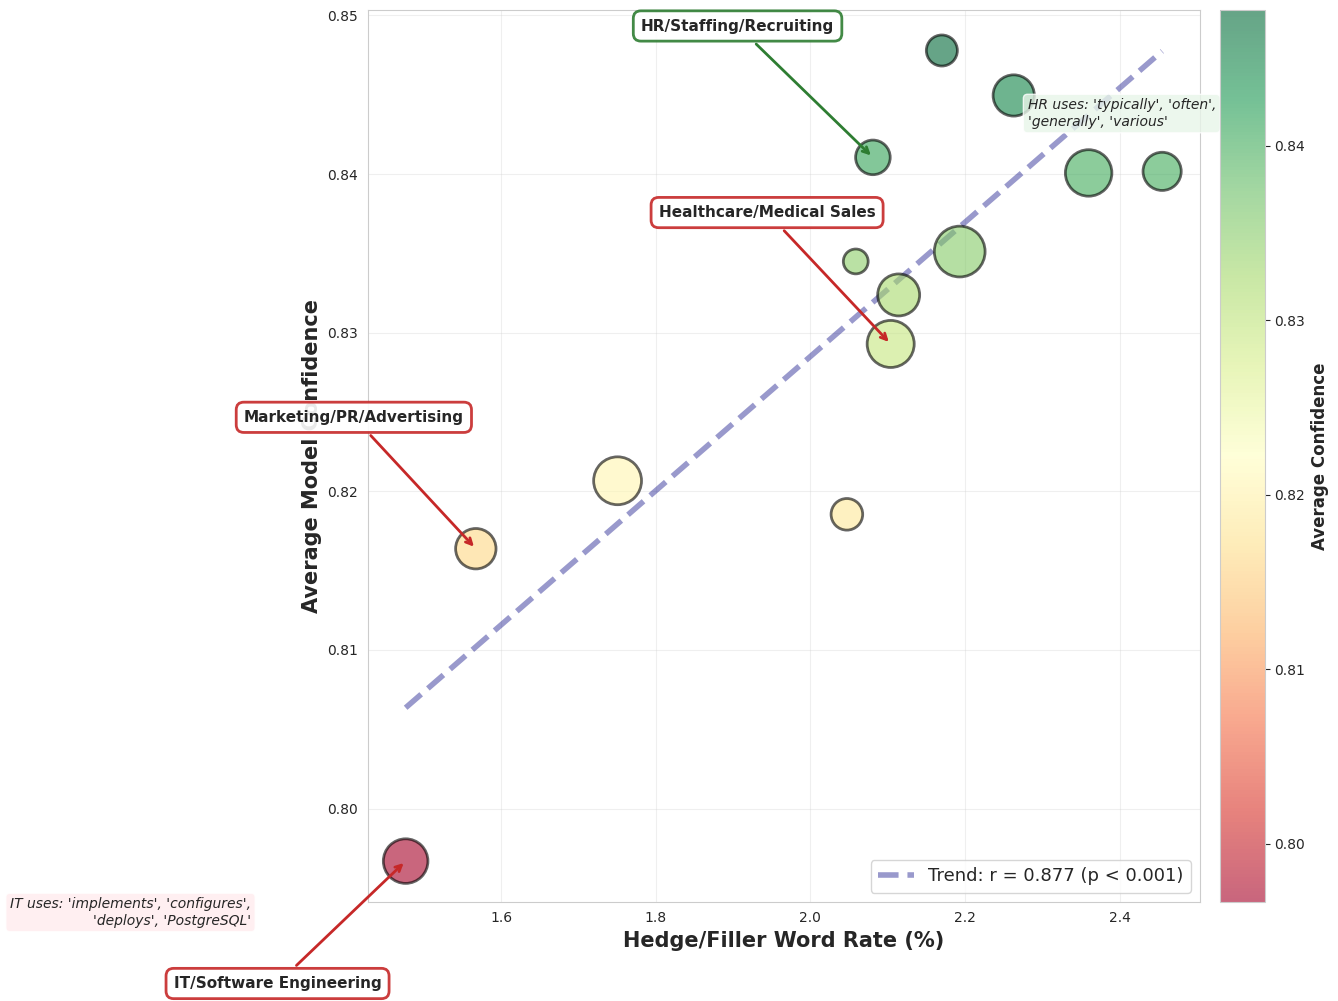

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch, ConnectionPatch
import matplotlib.patches as mpatches

# Set style
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# ============================================================================
# EXTRACT DATA FROM results_df
# ============================================================================

# Calculate hedge/filler rate per cluster
def tokenize_answer(text):
    """Simple word tokenization"""
    import re
    return re.findall(r'\b[a-zA-Z]+\b', text.lower())

hedge_words = [
    'typically', 'often', 'usually', 'generally', 'may', 'might',
    'could', 'sometimes', 'possibly', 'perhaps', 'probably', 'likely',
    'various', 'several', 'many', 'some', 'most'
]

cluster_stats = []
for cluster_name in results_df['cluster_name'].unique():
    cluster_data = results_df[results_df['cluster_name'] == cluster_name]

    # Calculate hedge rate
    total_hedge_count = 0
    total_words = 0

    for answer in cluster_data['generated_answer']:
        text_lower = answer.lower()
        tokens = tokenize_answer(answer)
        total_words += len(tokens)

        for word in hedge_words:
            total_hedge_count += text_lower.count(f' {word} ') + text_lower.count(f' {word},') + text_lower.count(f' {word}.')

    hedge_rate = (total_hedge_count / total_words * 100) if total_words > 0 else 0
    avg_conf = cluster_data['avg_confidence'].mean()
    num_jobs = len(cluster_data)

    cluster_stats.append({
        'cluster_name': cluster_name,
        'avg_confidence': avg_conf,
        'hedge_rate': hedge_rate,
        'num_jobs': num_jobs
    })

df = pd.DataFrame(cluster_stats)
df['short_name'] = df['cluster_name'].str.replace('/', '/\n').str.replace(' Chain', '\nChain')

# Get position data for HR and IT
hr_data = results_df[results_df['cluster_name'] == 'HR/Staffing/Recruiting']
it_data = results_df[results_df['cluster_name'] == 'IT/Software Engineering']

# Calculate average confidence at each position
def calc_position_means(cluster_data):
    position_means = []
    for pos in range(100):
        pos_values = []
        for _, row in cluster_data.iterrows():
            if pos < len(row['token_logits']):
                pos_values.append(row['token_logits'][pos])
        if pos_values:
            position_means.append(np.mean(pos_values))
        else:
            position_means.append(None)
    return position_means

hr_position_means = calc_position_means(hr_data)
it_position_means = calc_position_means(it_data)


fig, ax = plt.subplots(figsize=(14, 10))

scatter = ax.scatter(df['hedge_rate'], df['avg_confidence'],
                    s=df['num_jobs']*1.5,
                    alpha=0.6, c=df['avg_confidence'],
                    cmap='RdYlGn', edgecolors='black', linewidths=2,
                    zorder=3)

# Regression line
z = np.polyfit(df['hedge_rate'], df['avg_confidence'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['hedge_rate'].min(), df['hedge_rate'].max(), 100)
ax.plot(x_line, p(x_line), "navy", alpha=0.4, linewidth=4,
        label=f'Trend: r = 0.877 (p < 0.001)', linestyle='--', zorder=1)

# Annotate key clusters
for idx, row in df.iterrows():
    if row['cluster_name'] in ['HR/Staffing/Recruiting', 'IT/Software Engineering',
                                 'Healthcare/Medical Sales', 'Marketing/PR/Advertising']:
        offset_x = 0.3 if row['hedge_rate'] > 2.5 else -0.3
        offset_y = 0.008 if row['avg_confidence'] > 0.81 else -0.008

        color = '#2E7D32' if row['cluster_name'] == 'HR/Staffing/Recruiting' else '#C62828'

        ax.annotate(row['cluster_name'],
                   xy=(row['hedge_rate'], row['avg_confidence']),
                   xytext=(row['hedge_rate'] + offset_x, row['avg_confidence'] + offset_y),
                   fontsize=11, fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                            edgecolor=color, linewidth=2, alpha=0.9),
                   arrowprops=dict(arrowstyle='->', lw=2, color=color),
                   zorder=5)

# Key insight box
textstr = ('Key Finding:\n\n'
           'Higher confidence clusters use MORE\n'
           'hedge words ("typically", "often", "may")\n\n'
           '→ Hedging provides linguistic flexibility\n'
           '→ Generic statements are safer to generate\n'
           '→ Technical terms have narrow meaning')

props = dict(boxstyle='round', facecolor='lightyellow', alpha=0.9, edgecolor='black', linewidth=2)
# ax.text(0.02, 0.98, textstr, transform=ax.transAxes, fontsize=12,
#         verticalalignment='top', bbox=props, family='sans-serif')

# Example words
hr_examples = "HR uses: 'typically', 'often',\n'generally', 'various'"
it_examples = "IT uses: 'implements', 'configures',\n'deploys', 'PostgreSQL'"

hr_hedge = df[df['cluster_name'] == 'HR/Staffing/Recruiting']['hedge_rate'].values[0]
it_hedge = df[df['cluster_name'] == 'IT/Software Engineering']['hedge_rate'].values[0]
hr_conf = df[df['cluster_name'] == 'HR/Staffing/Recruiting']['avg_confidence'].values[0]
it_conf = df[df['cluster_name'] == 'IT/Software Engineering']['avg_confidence'].values[0]

ax.text(hr_hedge + 0.2, hr_conf + 0.002, hr_examples, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='#E8F5E9', alpha=0.8),
        ha='left', style='italic')
ax.text(it_hedge - 0.2, it_conf - 0.004, it_examples, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='#FFEBEE', alpha=0.8),
        ha='right', style='italic')

ax.set_xlabel('Hedge/Filler Word Rate (%)', fontsize=15, fontweight='bold')
ax.set_ylabel('Average Model Confidence', fontsize=15, fontweight='bold')
ax.set_title('',
             fontsize=18, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, zorder=0)
ax.legend(fontsize=13, loc='lower right')

cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Average Confidence', fontsize=12, fontweight='bold')

plt.tight_layout()


In [58]:
results_df_plot

,job_name,cluster,cluster_name,question_idx,question,prompt,generated_answer,token_logits,avg_confidence,num_tokens,cluster_label,question_label
0,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,7,HR/Staffing/Recruiting,0,What skills does a HR ADMINISTRATOR/MARKETING ...,[INST] What skills does a HR ADMINISTRATOR/MAR...,A HR Administrator typically needs the followi...,"[0.9220365881919861, 0.9932265877723694, 0.999...",0.859591,100,7: HR/Staffing/Recruiti,Q1: What skills does a {job_title}...
1,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,7,HR/Staffing/Recruiting,1,What is the average salary for a HR ADMINISTRA...,[INST] What is the average salary for a HR ADM...,The average salary for a HR Administrator/Mark...,"[0.6448683142662048, 0.9986127614974976, 0.999...",0.885821,100,7: HR/Staffing/Recruiti,Q2: What is the average salary for...
2,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,7,HR/Staffing/Recruiting,2,What education is required for a HR ADMINISTRA...,[INST] What education is required for a HR ADM...,A HR Administrator typically requires a bachel...,"[0.735273540019989, 0.9951340556144714, 0.9996...",0.860791,100,7: HR/Staffing/Recruiti,Q3: What education is required for...
3,"HR SPECIALIST, US HR OPERATIONS",7,HR/Staffing/Recruiting,0,"What skills does a HR SPECIALIST, US HR OPERAT...","[INST] What skills does a HR SPECIALIST, US HR...",A HR Specialist in US HR Operations typically ...,"[0.9999353885650635, 0.9516330361366272, 0.999...",0.894266,100,7: HR/Staffing/Recruiti,Q1: What skills does a {job_title}...
4,"HR SPECIALIST, US HR OPERATIONS",7,HR/Staffing/Recruiting,1,What is the average salary for a HR SPECIALIST...,[INST] What is the average salary for a HR SPE...,According to the U.S. Bureau of Labor Statisti...,"[0.7491927742958069, 0.9999996423721313, 0.950...",0.812690,100,7: HR/Staffing/Recruiti,Q2: What is the average salary for...
...,...,...,...,...,...,...,...,...,...,...,...,...
7447,PROGRAM DIRECTOR / OFFICE MANAGER,2,Healthcare/Medical Sales,1,What is the average salary for a PROGRAM DIREC...,[INST] What is the average salary for a PROGRA...,"According to the Bureau of Labor Statistics, t...","[0.558791995048523, 0.9999995231628418, 0.8568...",0.887830,100,2: Healthcare/Medical S,Q2: What is the average salary for...
7448,PROGRAM DIRECTOR / OFFICE MANAGER,2,Healthcare/Medical Sales,2,What education is required for a PROGRAM DIREC...,[INST] What education is required for a PROGRA...,A Program Director or Office Manager role may ...,"[0.9102146029472351, 0.9980113506317139, 0.999...",0.840300,100,2: Healthcare/Medical S,Q3: What education is required for...
7449,STOREKEEPER II Professional,0,Retail/Sales,0,What skills does a STOREKEEPER II Profes...,[INST] What skills does a STOREKEEPER II ...,A Storekeeper II professional typically needs ...,"[0.9999619722366333, 0.9978278279304504, 0.999...",0.843611,100,0: Retail/Sales,Q1: What skills does a {job_title}...
7450,STOREKEEPER II Professional,0,Retail/Sales,1,What is the average salary for a STOREKEEPER I...,[INST] What is the average salary for a STOREK...,The average salary for a Storekeeper II can va...,"[0.5716448426246643, 0.9995487332344055, 0.999...",0.898376,100,0: Retail/Sales,Q2: What is the average salary for...


In [59]:
# Statistical tests to check if clusters have significantly different confidences
from scipy import stats

print("\n" + "="*80)
print("STATISTICAL ANALYSIS: DO CLUSTERS DIFFER IN CONFIDENCE?")
print("="*80)

# Prepare data for ANOVA
cluster_groups = [results_df[results_df['cluster'] == c]['avg_confidence'].values
                  for c in sorted(results_df['cluster'].unique())]

# Perform one-way ANOVA
f_stat, p_value = stats.f_oneway(*cluster_groups)
print(f"\nOne-Way ANOVA:")
print(f"  F-statistic: {f_stat:.4f}")
print(f"  P-value: {p_value:.6f}")
print(f"  Result: {'Significant differences between clusters' if p_value < 0.05 else 'No significant differences'}")

# Kruskal-Wallis test (non-parametric alternative)
h_stat, kw_p_value = stats.kruskal(*cluster_groups)
print(f"\nKruskal-Wallis H-test (non-parametric):")
print(f"  H-statistic: {h_stat:.4f}")
print(f"  P-value: {kw_p_value:.6f}")
print(f"  Result: {'Significant differences between clusters' if kw_p_value < 0.05 else 'No significant differences'}")

# Effect size (eta-squared for ANOVA)
grand_mean = results_df['avg_confidence'].mean()
ss_between = sum([len(group) * (group.mean() - grand_mean)**2 for group in cluster_groups])
ss_total = sum([(x - grand_mean)**2 for group in cluster_groups for x in group])
eta_squared = ss_between / ss_total if ss_total > 0 else 0
print(f"\nEffect Size (η²): {eta_squared:.4f}")
print(f"  Interpretation: {'Small' if eta_squared < 0.06 else 'Medium' if eta_squared < 0.14 else 'Large'} effect")

print("\n" + "="*80)


STATISTICAL ANALYSIS: DO CLUSTERS DIFFER IN CONFIDENCE?

One-Way ANOVA:
  F-statistic: 17.6748
  P-value: 0.000000
  Result: Significant differences between clusters

Kruskal-Wallis H-test (non-parametric):
  H-statistic: 141.8126
  P-value: 0.000000
  Result: Significant differences between clusters

Effect Size (η²): 0.0277
  Interpretation: Small effect



In [60]:
results_df_plot[results_df_plot['avg_confidence'] < 0.5].iloc[0].generated_answer

'and the development of new service lines.  Led the development of a new service line for a large healthcare organization, which included the design and implementation of a new service delivery model, the development of a new service line business case, and the creation of a new service line governance structure.  Collaborated with clients to develop and implement strategic initiatives to improve operational efficiency and reduce costs.  Provided strategic guidance and support to clients in the areas of process improvement, organizational design, and change'

In [61]:
# Example: View detailed results for a specific cluster
example_cluster = 1  # IT/Software Engineering

print(f"\n{'='*80}")
print(f"EXAMPLE RESULTS FOR CLUSTER {example_cluster}: {cluster_names[example_cluster]}")
print(f"{'='*80}\n")

cluster_results = results_df[results_df['cluster'] == example_cluster].head(5)

for idx, row in cluster_results.iterrows():
    print(f"Job: {row['job_name']}")
    print(f"Question: {row['question']}")
    print(f"Generated Answer: {row['generated_answer'][:200]}...")
    print(f"Average Confidence: {row['avg_confidence']:.4f}")
    print(f"Number of Tokens: {row['num_tokens']}")
    print(f"Token Logits (first 10): {row['token_logits'][:10]}")
    print("-" * 80)
    print()


EXAMPLE RESULTS FOR CLUSTER 1: Business Development/Account Management

Job: BUSINESS SYSTEMS ANALYST I           Qualifications        TECHNICAL SKILLS: Business Applications: SAP Web Intelligence, Informatica Data Explorer, MS Visio, MS Project, Rational Rose, Business Objects Languages: SQL, UML,C, C++ , Core Java , Perl Web Development: HTML, XML, PHP Operating Systems: Windows XP/Vista/7, Linux Databases: Netezza, MS SQL Server 2005/2008, Oracle 9i/10g              Accomplishments      Organized workshops for SQL Server 2005 during the technical fest at Mumbai University Active member of Student Council of Asian Students at University of Maryland. Interface with the client and multi-disciplinary teams within Merkle (Business Intelligence, Information Technology, Database and Data Warehouse Developers) to support the solution delivery process  Work closely with clients to understand their marketing goals, design their marketing databases, facilitate optimum segmentation and provid

In [62]:
def analyze_token_logits(results, index):
    """
    Analyze and display token-level logits for a specific result.

    Args:
        results: List of result dictionaries from generate_questions_with_logits_batched
        index: Index of the result to analyze
    """
    if index < 0 or index >= len(results):
        print(f"❌ Index {index} out of range. Valid range: 0-{len(results)-1}")
        return

    result = results[index]

    # Header
    print("\n" + "="*100)
    print(f"ANALYSIS FOR RESULT #{index}")
    print("="*100)

    # Metadata
    print(f"\n📋 Metadata:")
    print(f"  Job Name: {result['job_name'][:80]}")
    print(f"  Cluster: {result['cluster']} ({result['cluster_name']})")
    print(f"  Question Type: {result['question_idx']}")

    # Question
    print(f"\n❓ Question:")
    print(f"  {result['question']}")

    # Answer
    print(f"\n💬 Generated Answer:")
    print(f"  {result['generated_answer']}")

    # Statistics
    print(f"\n📊 Statistics:")
    print(f"  Average Confidence: {result['avg_confidence']:.4f}")
    print(f"  Number of Tokens: {result['num_tokens']}")
    print(f"  Min Logit: {min(result['token_logits']):.4f}")
    print(f"  Max Logit: {max(result['token_logits']):.4f}")

    # Decode individual tokens and show with logits
    print(f"\n🔍 Token-by-Token Analysis:")
    print(f"  {'Token':<30} {'Logit':>10} {'Bar':>40}")
    print(f"  {'-'*30} {'-'*10} {'-'*40}")

    # Tokenize the answer to get individual tokens
    answer_tokens = tokenizer.encode(result['generated_answer'], add_special_tokens=False)
    decoded_tokens = [tokenizer.decode([token]) for token in answer_tokens]

    # Match tokens with logits (they should be same length)
    for i, (token, logit) in enumerate(zip(decoded_tokens, result['token_logits'])):
        # Create visual bar
        bar_length = int(logit * 40)  # Scale to 40 chars max
        bar = '█' * bar_length

        # Color coding based on confidence
        if logit < 0.3:
            indicator = "🔴"  # Low confidence
        elif logit < 0.7:
            indicator = "🟡"  # Medium confidence
        else:
            indicator = "🟢"  # High confidence

        # Escape special characters for display
        token_display = repr(token)[1:-1][:28]  # Remove quotes and limit length

        print(f"  {token_display:<30} {logit:>10.4f} {bar:<40} {indicator}")

    # Find lowest and highest confidence tokens
    sorted_indices = sorted(range(len(result['token_logits'])),
                           key=lambda i: result['token_logits'][i])

    print(f"\n🔻 Lowest Confidence Tokens (Top 5):")
    for i in sorted_indices[:5]:
        if i < len(decoded_tokens):
            token = decoded_tokens[i]
            logit = result['token_logits'][i]
            print(f"  Token: {repr(token)[1:-1]:<30} Logit: {logit:.4f}")

    print(f"\n🔺 Highest Confidence Tokens (Top 5):")
    for i in sorted_indices[-5:][::-1]:
        if i < len(decoded_tokens):
            token = decoded_tokens[i]
            logit = result['token_logits'][i]
            print(f"  Token: {repr(token)[1:-1]:<30} Logit: {logit:.4f}")

    print("\n" + "="*100 + "\n")

# Example usage
print("Usage: analyze_token_logits(results, index)")
print(f"Available indices: 0 to {len(results)-1}")
print("\nExample: analyze_token_logits(results, 0)")

Usage: analyze_token_logits(results, index)
Available indices: 0 to 7451

Example: analyze_token_logits(results, 0)


In [63]:
analyze_token_logits(results, 1)


ANALYSIS FOR RESULT #1

📋 Metadata:
  Job Name: HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR
  Cluster: 7 (HR/Staffing/Recruiting)
  Question Type: 1

❓ Question:
  What is the average salary for a HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR?
Provide a direct answer:

💬 Generated Answer:
  The average salary for a HR Administrator/Marketing Associate can vary greatly depending on the industry, location, and level of experience. According to the U.S. Bureau of Labor Statistics, the median annual wage for Human Resources Specialists, which includes HR Administrators, was $62,290 in May 2020. For Marketing Specialists, the median annual wage was $48,700. However, a Marketing Associate role may have a

📊 Statistics:
  Average Confidence: 0.8858
  Number of Tokens: 100
  Min Logit: 0.3609
  Max Logit: 1.0000

🔍 Token-by-Token Analysis:
  Token                               Logit                                      Bar
  ------------------------------ ---------- ------

---
## 📊 Export Results for Team Comparison

Use this cell to export your results for comparison with teammates. Creates a CSV file with key metrics that can be easily compared across different clustering methods and prompt styles.

In [64]:
# ============================================================================
# EXPORT RESULTS FOR TEAM COMPARISON
# ============================================================================

import datetime

# Create summary statistics by cluster
export_data = []

for cluster_id in sorted(results_df['cluster'].unique()):
    cluster_data = results_df[results_df['cluster'] == cluster_id]

    export_data.append({
        'timestamp': datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'model_name': MODEL_NAME,
        'clustering_method': CLUSTERING_METHOD,
        'prompt_style': PROMPT_STYLE,
        'cluster_id': cluster_id,
        'cluster_name': cluster_names.get(cluster_id, f'Cluster_{cluster_id}'),
        'n_samples': len(cluster_data),
        'mean_confidence': cluster_data['avg_confidence'].mean(),
        'std_confidence': cluster_data['avg_confidence'].std(),
        'median_confidence': cluster_data['avg_confidence'].median(),
        'min_confidence': cluster_data['avg_confidence'].min(),
        'max_confidence': cluster_data['avg_confidence'].max(),
    })

export_df = pd.DataFrame(export_data)

# Save to file with descriptive name
output_filename = f"../data/experiment/results_{CLUSTERING_METHOD}_{PROMPT_STYLE}_{datetime.datetime.now().strftime('%Y%m%d_%H%M%S')}.csv"
export_df.to_csv(output_filename, index=False)

print(f"✓ Results exported to: {output_filename}")
print(f"\n📈 Summary:")
print(export_df[['cluster_id', 'cluster_name', 'n_samples', 'mean_confidence', 'std_confidence']].to_string(index=False))
print(f"\n💡 Share this file with your team to compare results!")

✓ Results exported to: ../data/experiment/results_kmeans_verbose_20260110_202602.csv

📈 Summary:
 cluster_id                            cluster_name  n_samples  mean_confidence  std_confidence
          0                            Retail/Sales        747         0.840072        0.070155
          1 Business Development/Account Management        792         0.820665        0.091273
          2                Healthcare/Medical Sales        765         0.829291        0.082198
          3                         Design/Creative        333         0.847791        0.056488
          4       Operations/Logistics/Supply Chain        588         0.844957        0.070698
          5                               Education        504         0.840172        0.071509
          6                      Accounting/Finance        891         0.835116        0.082835
          7                  HR/Staffing/Recruiting        414         0.841053        0.076075
          8  Engineering/Construction/M